In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import xarray as xr
from torch import nn
import torch.nn.functional as F

# Introduction

## Brief

1. Find some weather/climate data. Be
adventurous!

2. Get an LLM to help you write
PyTorch code that runs a
transformer (use time series data) or
an autoencoder (use gridded data)

3. Compare both against a suitable
baseline and evaluate performance

4. Submit your presentation and
Python notebook to the Google
Form.

5. Present in your group for 5 minutes


__We have chosen to use a variational autoencoder to investigate ocean states__

<h1>Data Preprocessing<h1>

In [3]:
pacific_centre_long = 200
pacific_centre_lat = -2

In [4]:
v_box_size = 128
h_box_size = 256

In [5]:
ds = xr.open_dataset('data/data.grib')


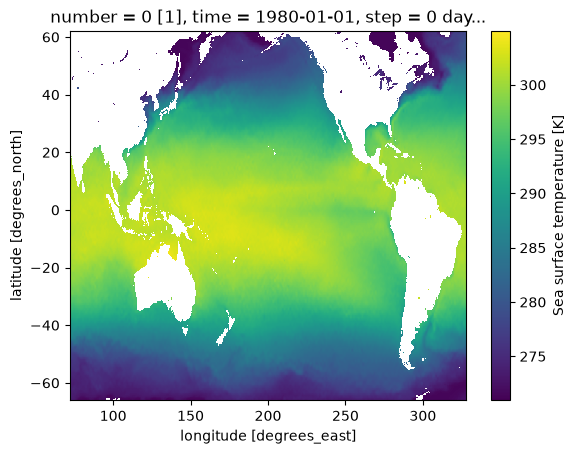

In [6]:
ds_pacific = ds.sel(latitude=slice(pacific_centre_lat + v_box_size/2, pacific_centre_lat - v_box_size/2), longitude=slice(pacific_centre_long - h_box_size/2, pacific_centre_long + h_box_size/2))
ds_pacific.sst[0].plot()

In [7]:
ds_pacific = ds_pacific.coarsen(latitude=2, longitude=4, boundary="trim").mean()

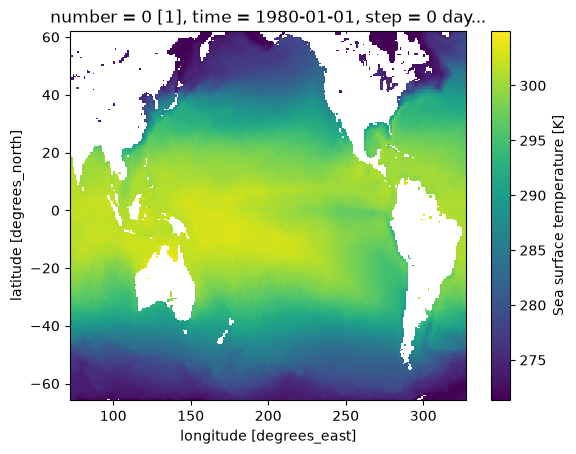

In [8]:
ds_pacific.sst[0].plot()

In [9]:
ds_mean = ds_pacific.sst.mean(dim=['latitude', 'longitude'])
ds_pacific_anomaly = ds_pacific - ds_mean

While cleaning the data I was unexpectedly reminded of climate change when observing the mean SST

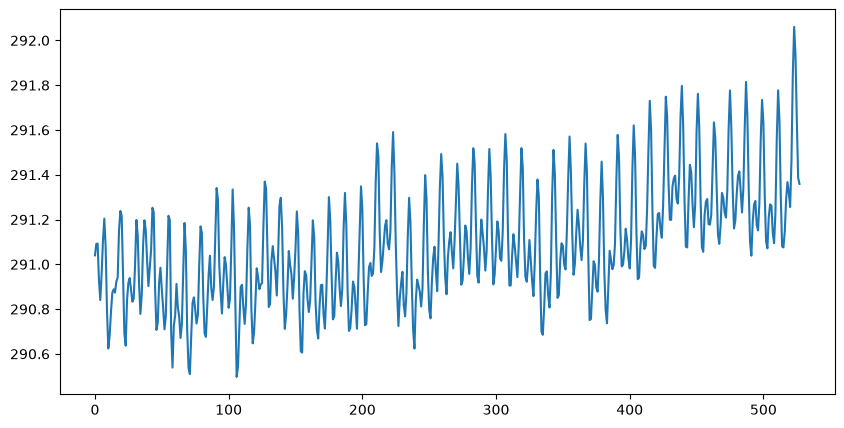

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ds_mean, label='Mean SST')

Text(0.5, 1.0, 'Pacific Sea Surface Temperature anomaly (SSTA) at time step 500')

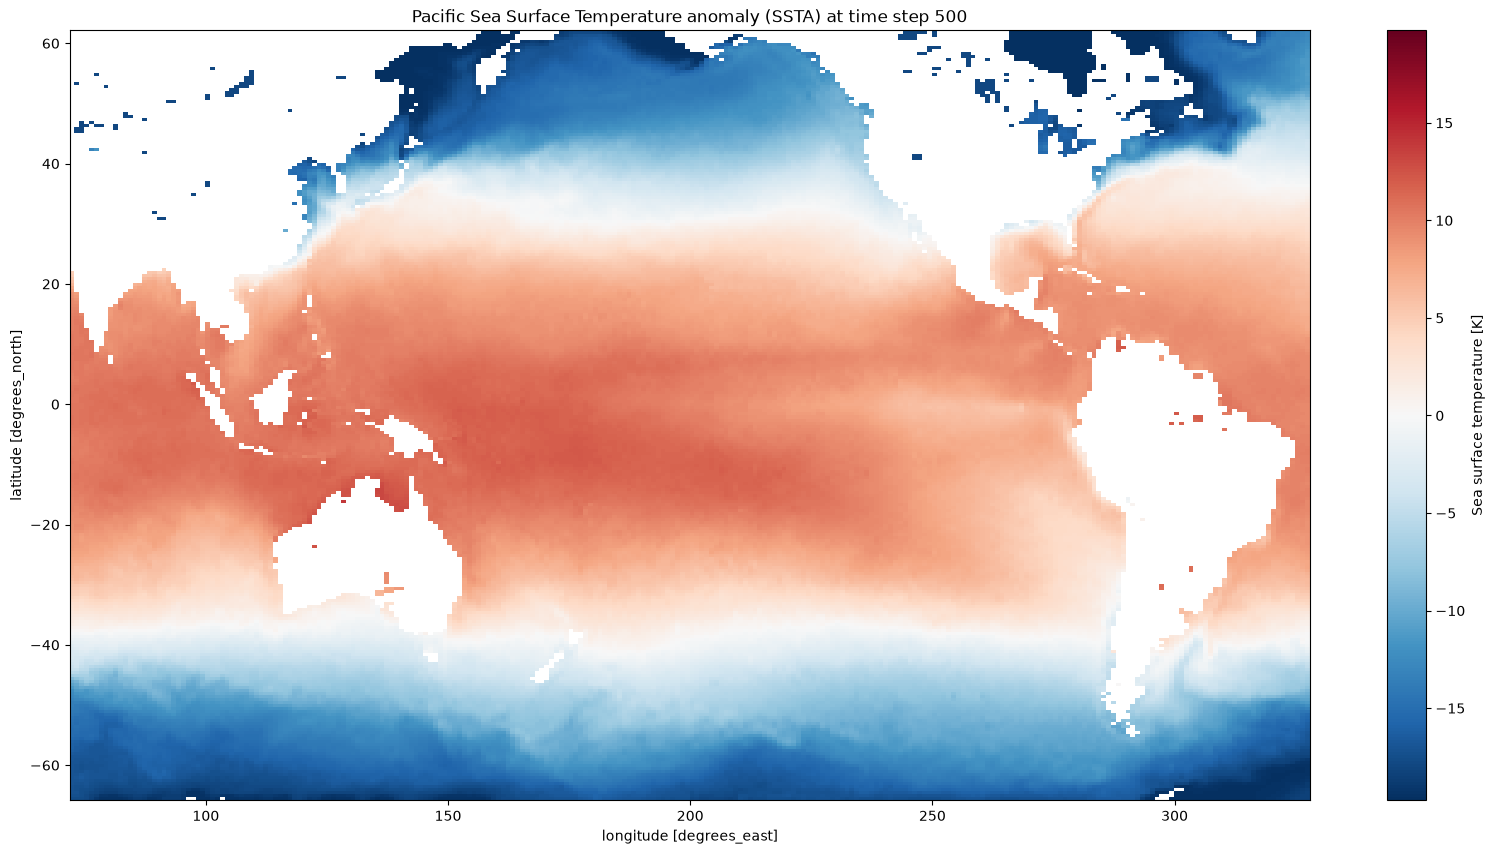

In [11]:
fig2, ax2 = plt.subplots(figsize=(20, 10))
ds_pacific_anomaly.sst[0].plot(ax=ax2)
ax2.set_title('Pacific Sea Surface Temperature anomaly (SSTA) at time step 500')

<h1>Variational Convolutional Autoencoder<h1>

In [12]:
latent_dim = 2

In [ ]:
class ConvVAE(nn.Module):
    def __init__(self,k=latent_dim):
        super().__init__()
        self.c_encode = nn.Sequential(
            nn.Conv2d(1,32,3,stride=2,padding=1), nn.LeakyReLU(0.2),
            nn.Conv2d(32,64,3,stride=2,padding=1), nn.LeakyReLU(0.2),
            nn.Conv2d(64,128,3,stride=2,padding=1), nn.LeakyReLU(0.2),
            nn.Conv2d(128,256,3,stride=2,padding=1), nn.LeakyReLU(0.2),
            nn.Conv2d(256,512,3,stride=2,padding=1), nn.LeakyReLU(0.2),
        )
        self.mu = nn.Linear(512*8*8, k)
        self.logvar = nn.Linear(512*8*8, k)
        self.from_code = nn.Linear(k, 512*8*8)
        self.c_decode = nn.Sequential(
            nn.ConvTranspose2d(512,256,3,stride=2,padding=1,output_padding=1), nn.LeakyReLU(0.2),
            nn.ConvTranspose2d(256,128,3,stride=2,padding=1,output_padding=1), nn.LeakyReLU(0.2),
            nn.ConvTranspose2d(128,64,3,stride=2,padding=1,output_padding=1), nn.LeakyReLU(0.2),
            nn.ConvTranspose2d(64,32,3,stride=2,padding=1,output_padding=1), nn.LeakyReLU(0.2),
            nn.ConvTranspose2d(32, 1,3,stride=2,padding=1,output_padding=1), 
        )
    
    def encode(self,x):
        h = self.c_encode(x).flatten(1)
        return self.mu(h), self.logvar(h)
    
    def decode(self,z):
        h = F.leaky_relu(self.from_code(z), 0.2).view(-1,512,8,8)
        return self.c_decode(h)

    def forward(self,x):
        mu, logvar = self.encode(x)
        std = torch.exp(0.5*logvar)
        eps = torch.randn_like(std)
        z = mu + eps*std
        return self.decode(z), mu, logvar


### Variational KL Part

In [14]:
def kl_diag_gaussian(mu, logvar):
    """Slide 18, one code, summed over the k latent dimensions."""
    return 0.5 * (mu ** 2 + np.exp(logvar) - 1.0 - logvar).sum()